# 02 Train the models (notebook version of `src/train_models.py`)

Same models, same technique, same split. Only the layout changes: create each model, fit it, print its training and test scores.

1. Split **vendors** (not applications) 70/15/15 into train, validation and test, balanced by persona.
2. Tune each model on the training vendors only, with 5-fold cross-validation grouped by vendor.
3. Fit the best setting on train. The validation set sets the approval cutoff. The test set is scored once.
4. Compare logistic regression, random forest, XGBoost, a one-feature rule baseline and the visible scorecard baseline.

Only the columns in `feature_columns.json` under `features` are model inputs. Persona, gender, business type and every outcome or hidden column are never inputs. The labels are simulated, so the scores show how well the models recover the simulated outcome, not performance on real borrowers.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

# Google Colab only: mount Drive and move into the project folder (does nothing on your own computer)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/mpesa-credit-scoring-colab")
except ImportError:
    pass

# Find the project folder wherever the kernel started (project folder, notebooks folder, or the folder above the project)
DATA = os.path.join("data", "processed", "features.parquet")
for cand in (".", "..", "mpesa-credit-scoring", os.path.join("..", "mpesa-credit-scoring")):
    if os.path.exists(os.path.join(cand, DATA)):
        os.chdir(cand)
        break
else:
    raise FileNotFoundError(f"could not find {DATA} from {os.getcwd()}; open the notebook from the mpesa-credit-scoring folder")
print("working folder:", os.getcwd())

working folder: c:\Users\delam\credit_score_project\mpesa-credit-scoring


## 1. Load the features and split by vendor

In [2]:
SEED = 42
feat = pd.read_parquet("data/processed/features.parquet")
F = json.load(open("data/processed/feature_columns.json"))["features"]

banned = {"persona", "latent_risk", "txn_type_true", "gender", "business_type", "defaulted", "days_past_due", "late_or_default",
          "repayment_status", "scorecard_p", "scorecard_score", "hidden_shock", "fuliza_late", "fuliza_n_draws",
          "fuliza_max_lag_days", "window_complete"}
assert not banned & set(F), f"banned columns in features: {banned & set(F)}"

def split_vendors(feat, seed, splits=(0.70, 0.15, 0.15)):
    rng = np.random.default_rng(seed)
    assign = {}
    for _, g in feat.drop_duplicates("vendor_id").groupby("persona"):      # balanced by persona
        ids = g.vendor_id.to_numpy().copy()
        rng.shuffle(ids)
        n = len(ids)
        n_tr, n_va = int(round(splits[0] * n)), int(round(splits[1] * n))
        for i, v in enumerate(ids):
            assign[v] = "train" if i < n_tr else "val" if i < n_tr + n_va else "test"
    return assign

feat["split"] = feat.vendor_id.map(split_vendors(feat, SEED))
assert not (feat.groupby("vendor_id").split.nunique() > 1).any(), "a vendor is in two splits"
tr, va, te = (feat[feat.split == s] for s in ("train", "val", "test"))

X_train, y_train, g_train = tr[F], tr.defaulted.astype(int), tr.vendor_id
X_val,   y_val  = va[F], va.defaulted.astype(int).to_numpy()
X_test,  y_test = te[F], te.defaulted.astype(int).to_numpy()

pd.DataFrame([{"split": s, "vendors": d.vendor_id.nunique(), "applications": len(d),
               "defaults": int(d.defaulted.sum()), "default_rate": round(d.defaulted.mean(), 3)}
              for s, d in (("train", tr), ("val", va), ("test", te))])

,split,vendors,applications,defaults,default_rate
0,train,700,1561,275,0.176
1,val,151,336,48,0.143
2,test,149,347,64,0.184


## 2. Helper functions
Metrics, a vendor-level bootstrap for the AUC interval, and the lender-view helper. They are the same as in `src/train_models.py`.

In [3]:
def proba(model, X):
    return model.predict_proba(X)[:, 1]

def metrics(y, p):
    y = np.asarray(y)
    return {"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "KS": float(ks_2samp(p[y == 1], p[y == 0]).statistic), "Brier": brier_score_loss(y, np.clip(p, 0, 1))}

def bootstrap_auc(y, p, vendors, n=1000, seed=0):
    rng = np.random.default_rng(seed)                  # resample vendors, with all their applications together
    df = pd.DataFrame({"y": y, "p": p, "v": vendors})
    by = {v: g for v, g in df.groupby("v")}
    ids = np.array(list(by))
    vals = []
    for _ in range(n):
        d = pd.concat([by[v] for v in rng.choice(ids, len(ids))])
        if 0 < d.y.sum() < len(d):
            vals.append(roc_auc_score(d.y, d.p))
    return tuple(np.percentile(vals, [2.5, 97.5]))

def bad_rate_at(y, p, cutoff):
    approved = p <= cutoff
    return float(approved.mean()), (float(y[approved].mean()) if approved.any() else np.nan)

## 3. Create the models
`make_model` builds each model with the project's settings. Missing values are filled with the median (and a missing-value flag is added). Logistic regression also rank-normalises its inputs. XGBoost handles missing values itself.

In [4]:
def make_model(name, **p):
    imp = SimpleImputer(strategy="median", add_indicator=True)
    if name == "logistic":
        return Pipeline([("imp", imp), ("q", QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=0)),
                         ("m", LogisticRegression(C=p.get("C", 0.1), max_iter=3000))])
    if name == "random_forest":
        return Pipeline([("imp", imp), ("m", RandomForestClassifier(
            n_estimators=p.get("n_estimators", 500), min_samples_leaf=p.get("min_samples_leaf", 5),
            max_features="sqrt", n_jobs=-1, random_state=0))])
    if name == "xgboost":
        return XGBClassifier(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth", 3), learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=2, eval_metric="logloss",
                             tree_method="hist", n_jobs=-1, random_state=0)
    raise ValueError(name)

grids = {"logistic": [{"C": c} for c in (0.01, 0.03, 0.1, 0.3, 1.0)],
         "random_forest": [{"min_samples_leaf": m} for m in (3, 5, 10)],
         "xgboost": [{"max_depth": d, "n_estimators": n} for d, n in ((2, 200), (3, 200), (3, 400))]}

## 4. Tune on the training vendors only, then fit
Each setting is scored by 5-fold cross-validation grouped by vendor (a vendor's applications never sit in both the fitting and the scoring part of a fold). The setting with the best mean AUC is fitted on the whole training set.

In [5]:
def cv_auc(name, params, X, y, groups, seed):
    skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    s = []
    for a, b in skf.split(X, y, groups):
        m = make_model(name, **params).fit(X.iloc[a], y.iloc[a])
        s.append(roc_auc_score(y.iloc[b], proba(m, X.iloc[b])))
    return float(np.mean(s)), float(np.std(s))

best, tune_rows = {}, []
for name, grid in grids.items():
    scored = [(cv_auc(name, p, X_train, y_train, g_train, SEED), p) for p in grid]
    (m, s), p = max(scored, key=lambda t: t[0][0])
    best[name] = p
    tune_rows.append({"model": name, "best_settings": str(p), "cv_auc_mean": round(m, 3), "cv_auc_sd": round(s, 3)})
pd.DataFrame(tune_rows)

,model,best_settings,cv_auc_mean,cv_auc_sd
0,logistic,{'C': 0.01},0.708,0.029
1,random_forest,{'min_samples_leaf': 10},0.716,0.035
2,xgboost,"{'max_depth': 2, 'n_estimators': 200}",0.703,0.034


In [6]:
LR  = make_model("logistic", **best["logistic"])
RF  = make_model("random_forest", **best["random_forest"])
XGB = make_model("xgboost", **best["xgboost"])

LR.fit(X_train, y_train)
RF.fit(X_train, y_train)
XGB.fit(X_train, y_train)
print("models fitted")

models fitted


## 5. Training and test scores

In [7]:
fitted = {"logistic": LR, "random_forest": RF, "xgboost": XGB}
for name, m in fitted.items():
    print(f"{name} training accuracy: {m.score(X_train, y_train):.3f}   test accuracy: {m.score(X_test, y_test):.3f}")
    print(f"{name} training AUC:      {roc_auc_score(y_train, proba(m, X_train)):.3f}   test AUC:      {roc_auc_score(y_test, proba(m, X_test)):.3f}")
    print()
print("Always predicting 'no default' gives test accuracy", round(1 - y_test.mean(), 3), "and AUC 0.5.")
print("A big gap between training and test AUC means overfitting.")

logistic training accuracy: 0.825   test accuracy: 0.810
logistic training AUC:      0.741   test AUC:      0.759

random_forest training accuracy: 0.868   test accuracy: 0.801
random_forest training AUC:      0.943   test AUC:      0.732

xgboost training accuracy: 0.863   test accuracy: 0.816
xgboost training AUC:      0.872   test AUC:      0.713

Always predicting 'no default' gives test accuracy 0.816 and AUC 0.5.
A big gap between training and test AUC means overfitting.


## 6. Compare with the two baselines (validation and test)
`rule_baseline` ranks vendors by their share of near-zero-balance days, with no fitting. `scorecard_baseline` is the visible cash-flow scorecard (features and weights only, no hidden terms), also with no fitting. A model should beat both clearly to justify its complexity. The intervals come from resampling test vendors 1,000 times.

In [8]:
P_va = {n: proba(m, X_val) for n, m in fitted.items()}
P_te = {n: proba(m, X_test) for n, m in fitted.items()}
col = "near_zero_day_share_90"
fill = float(tr[col].median())
P_va["rule_baseline"] = va[col].fillna(fill).to_numpy()
P_te["rule_baseline"] = te[col].fillna(fill).to_numpy()
names = ["logistic", "random_forest", "xgboost", "rule_baseline"]
if "scorecard_score" in feat.columns:
    P_va["scorecard_baseline"] = va.scorecard_score.to_numpy()
    P_te["scorecard_baseline"] = te.scorecard_score.to_numpy()
    names.append("scorecard_baseline")

rows = []
for n in names:
    mva, mte = metrics(y_val, P_va[n]), metrics(y_test, P_te[n])
    lo, hi = bootstrap_auc(y_test, P_te[n], te.vendor_id.to_numpy(), n=1000)
    rows.append({"model": n, "val AUC": mva["AUC"], "test AUC": mte["AUC"], "test AUC 95% low": lo, "test AUC 95% high": hi,
                 "test PR-AUC": mte["PR-AUC"], "test KS": mte["KS"],
                 "test Brier": mte["Brier"] if n not in ("rule_baseline", "scorecard_baseline") else np.nan})
results = pd.DataFrame(rows).set_index("model").round(3)
print("defaults in the test set:", int(y_test.sum()), "of", len(y_test))
results

defaults in the test set: 64 of 347


,val AUC,test AUC,test AUC 95% low,test AUC 95% high,test PR-AUC,test KS,test Brier
model,,,,,,,
logistic,0.725,0.759,0.686,0.825,0.403,0.455,0.131
random_forest,0.695,0.732,0.658,0.798,0.340,0.492,0.137
xgboost,0.664,0.713,0.632,0.787,0.369,0.412,0.136
rule_baseline,0.728,0.772,0.699,0.835,0.410,0.441,NaN
scorecard_baseline,0.731,0.770,0.696,0.836,0.440,0.483,NaN


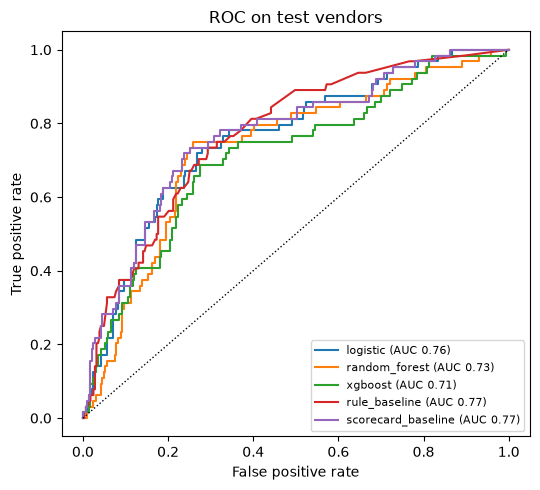

In [9]:
plt.figure(figsize=(5.5, 5))
for n in names:
    fpr, tpr, _ = roc_curve(y_test, P_te[n])
    plt.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, P_te[n]):.2f})")
plt.plot([0, 1], [0, 1], "k:", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC on test vendors")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

## 7. Lender view
The approval cutoff is set on the validation set so that the target share is approved, then applied to the test set. This shows the default rate among approved applicants.

In [10]:
print("default rate with no scoring on test:", round(y_test.mean(), 3))
lend = []
for n in names:
    for r in (0.70, 0.80, 0.90):
        cutoff = float(np.quantile(P_va[n], r))
        ar, br = bad_rate_at(y_test, P_te[n], cutoff)
        lend.append({"model": n, "approval target": f"{r:.0%}", "actual approval on test": round(ar, 3), "default rate among approved": round(br, 3)})
pd.DataFrame(lend)

default rate with no scoring on test: 0.184


,model,approval target,actual approval on test,default rate among approved
0,logistic,70%,0.646,0.080
1,logistic,80%,0.758,0.110
2,logistic,90%,0.888,0.149
3,random_forest,70%,0.663,0.078
4,random_forest,80%,0.778,0.133
5,random_forest,90%,0.885,0.160
6,xgboost,70%,0.651,0.093
7,xgboost,80%,0.772,0.134
8,xgboost,90%,0.865,0.147
9,rule_baseline,70%,0.657,0.088


## 8. Do the models separate vendors inside each persona?
Out-of-fold AUC on train + validation, computed within each persona. If the models only recognised which persona a vendor belongs to, these numbers would sit near 0.5.

In [11]:
dev = pd.concat([tr, va])
Xd, yd, gd = dev[F], dev.defaulted.astype(int), dev.vendor_id

def oof_predictions(name, params):
    out = np.zeros(len(yd))
    for a, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xd, yd, gd):
        out[b] = proba(make_model(name, **params).fit(Xd.iloc[a], yd.iloc[a]), Xd.iloc[b])
    return out

oof = {n: oof_predictions(n, best[n]) for n in fitted}
print("overall out-of-fold AUC:", {n: round(roc_auc_score(yd, p), 3) for n, p in oof.items()})
pers = []
for ps, g in dev.groupby("persona"):
    idx = np.where(dev.persona.to_numpy() == ps)[0]
    yy = yd.to_numpy()[idx]
    row = {"persona": ps, "applications": len(g), "default_rate": round(g.defaulted.mean(), 3)}
    for n in oof:
        row[n] = round(roc_auc_score(yy, oof[n][idx]), 3) if 0 < yy.sum() < len(yy) else np.nan
    pers.append(row)
pd.DataFrame(pers).set_index("persona")

overall out-of-fold AUC: {'logistic': 0.71, 'random_forest': 0.708, 'xgboost': 0.7}


,applications,default_rate,logistic,random_forest,xgboost
persona,,,,,
growing,344,0.070,0.455,0.513,0.542
new,129,0.171,0.434,0.531,0.560
seasonal,384,0.185,0.630,0.608,0.576
stable,591,0.078,0.539,0.506,0.524
struggling,449,0.356,0.584,0.579,0.555


## 9. What the models use

In [12]:
print("XGBoost importance (gain, top 12):")
print(pd.Series(XGB.feature_importances_, index=F).sort_values(ascending=False).head(12).round(3).to_string())
print()
names_lr = list(F) + [f"{F[i]} (missing flag)" for i in LR.named_steps["imp"].indicator_.features_]
coef = pd.Series(LR.named_steps["m"].coef_[0], index=names_lr)
print("Logistic regression coefficients (inputs are rank-normalised, so sizes are comparable; positive = higher risk):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(2).to_string())

XGBoost importance (gain, top 12):
near_zero_day_share_30    0.102
near_zero_day_share_90    0.094
near_zero_day_share_60    0.074
debt_service_ratio_90     0.048
fuliza_funded_share_90    0.033
fuliza_draws_60           0.027
income_total_90           0.025
balance_cv_90             0.024
median_ticket_90          0.022
fuliza_draws_30           0.021
income_count_90           0.018
balance_median_eod_90     0.017

Logistic regression coefficients (inputs are rank-normalised, so sizes are comparable; positive = higher risk):
withdraw_share_of_income_30                       0.13
balance_cv_90                                     0.12
withdraw_share_of_income_60                      -0.10
days_since_last_fuliza_draw                      -0.09
weekly_income_cv_90                               0.09
near_zero_day_share_60                            0.08
essential_outflow_share_90                       -0.07
fuliza_repay_lag_median_days_90 (missing flag)    0.07
amount_to_income_30         

## Reading the results
- Check the number of test defaults first. With a few dozen, the AUC intervals are wide (about ±0.07), and a difference of a few points between models is noise.
- Compare every model with `scorecard_baseline` and `rule_baseline`. The labels come from the scorecard plus hidden terms, so the scorecard is close to the best possible score.
- All outcomes are simulated. These numbers show how well the models recover the simulated labels, not performance on real borrowers.